In [32]:
import requests
import os
import json
from datetime import datetime, timezone
from matplotlib import pyplot as plt

In [33]:
def get_data():
    # With requests, we can ask the web service for the data.
    # Can you understand the parameters we are passing here?
    response = requests.get(
        "http://earthquake.usgs.gov/fdsnws/event/1/query.geojson",
        params={
            'starttime': "2000-01-01",
            "maxlatitude": "58.723",
            "minlatitude": "50.008",
            "maxlongitude": "1.67",
            "minlongitude": "-9.756",
            "minmagnitude": "1",
            "endtime": "2018-10-11",
            "orderby": "time-asc"}
    )

    # The response we get back is an object with several fields.
    # The actual contents we care about are in its text field:
    data = response.json()
    with open('data.json', "w") as f:
        json.dump(data, f, indent=4)
    # To understand the structure of this text, you may want to save it
    # to a file and open it in VS Code or a browser.
    # See the README file for more information.
    # We need to interpret the text to get values that we can work with.
    # What format is the text in? How can we load the values?
    return data

In [34]:
def count_earthquakes(data):
    """Get the total number of earthquakes in the response."""
    return data['metadata']['count']




In [35]:
def get_magnitude(earthquake):
    """Retrive the magnitude of an earthquake item."""
    return earthquake['properties']['mag']




In [36]:
def get_location(earthquake):
    """Retrieve the latitude and longitude of an earthquake item."""
    # There are three coordinates, but we don't care about the third (altitude)
    return earthquake['geometry']['coordinates'][1], earthquake['geometry']['coordinates'][0]




In [37]:
def get_maximum(data):
    """Get the magnitude and location of the strongest earthquake in the data."""
    # We can use the max function to find the earthquake with the largest magnitude.
    # The key argument tells max how to compare earthquakes.
    strongest = max(data['features'], key=get_magnitude)
    return get_magnitude(strongest), get_location(strongest)




In [38]:
# With all the above functions defined, we can now call them and get the result
data = get_data()
print(f"Loaded {count_earthquakes(data)}")
max_magnitude, max_location = get_maximum(data)
print(f"The strongest earthquake was at {max_location} with magnitude {max_magnitude}")

Loaded 120
The strongest earthquake was at (52.52, -2.15) with magnitude 4.8


In [39]:
def get_frequncy_year(data):
    """Get the number of earthquakes per year."""
    frequency = {}
    for earthquake in data['features']:
        time = datetime.fromtimestamp(earthquake["properties"]["time"] / 1000, tz=timezone.utc)
        year = time.year
        if year not in frequency:
            frequency[year] = 0
        frequency[year] += 1
    return frequency

In [40]:
def average_magnitude_year(data):
    """Get the average magnitude of earthquakes per year."""
    magnitude_sum = {}
    count = {}
    for earthquake in data['features']:
        time = datetime.fromtimestamp(earthquake["properties"]["time"] / 1000, tz=timezone.utc)
        year = time.year
        magnitude = earthquake['properties']['mag']
        if year not in magnitude_sum:
            magnitude_sum[year] = 0
            count[year] = 0
        magnitude_sum[year] += magnitude
        count[year] += 1
    average_magnitude = {year: magnitude_sum[year] / count[year] for year in magnitude_sum}
    return average_magnitude

In [41]:
def plot_earthquake_frequency(data):
    """Plot the number of earthquakes per year."""
    frequency = get_frequncy_year(data)
    years = sorted(frequency.keys())
    counts = [frequency[year] for year in years]
    
    plt.figure(figsize=(10, 5))
    plt.bar(years, counts)
    plt.xlabel('Year')
    plt.ylabel('Number of Earthquakes')
    plt.title('Number of Earthquakes per Year')
    plt.xticks(years, rotation=45)
    plt.tight_layout()
    plt.show()

In [42]:
def plot_average_magnitude(data):
    """Plot the average magnitude of earthquakes per year."""
    average_magnitude = average_magnitude_year(data)
    years = sorted(average_magnitude.keys())
    magnitudes = [average_magnitude[year] for year in years]
    
    plt.figure(figsize=(10, 5))
    plt.plot(years, magnitudes, marker='o')
    plt.xlabel('Year')
    plt.ylabel('Average Magnitude')
    plt.title('Average Magnitude of Earthquakes per Year')
    plt.xticks(years, rotation=45)
    plt.tight_layout()
    plt.show()

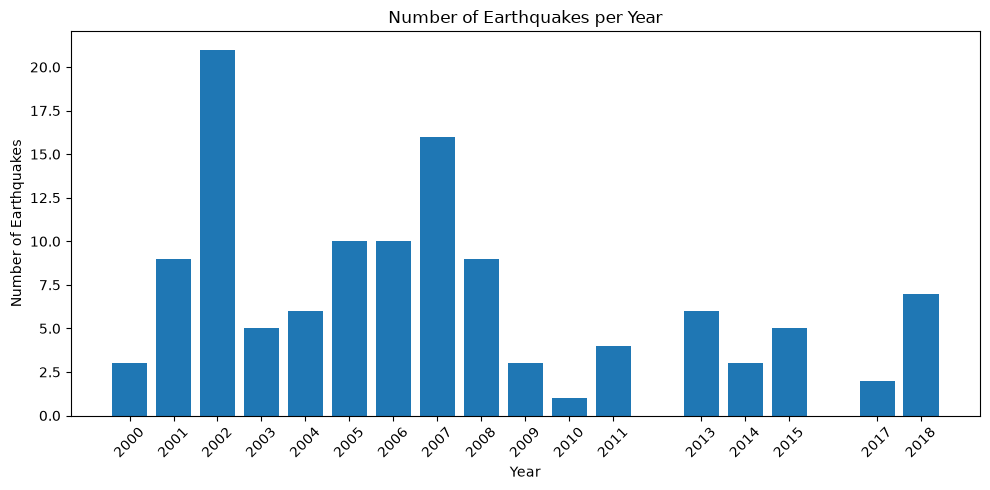

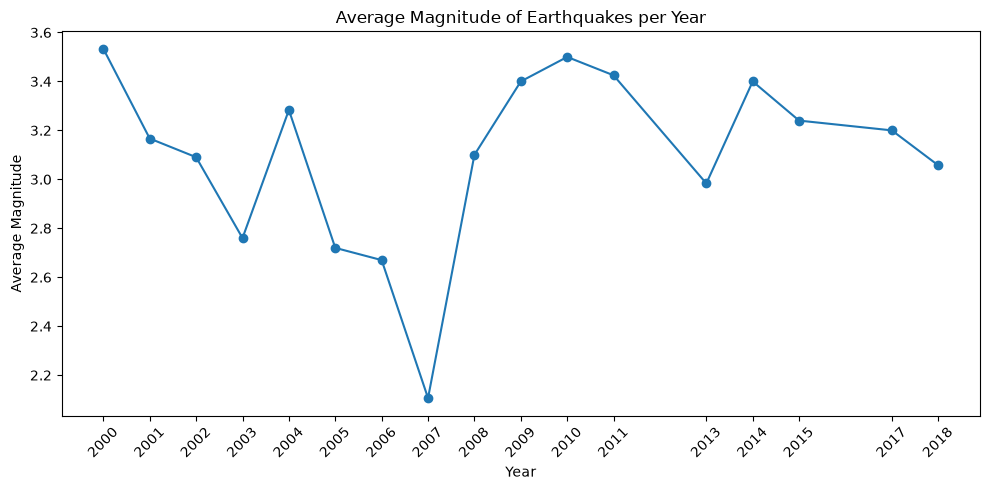

In [43]:
plot_earthquake_frequency(data)
plot_average_magnitude(data)